# 05 — Explanations and expensive errors

Use only the existing selection predictions and fitted tree models. The [approve/cancel scenario](../docs/cost-scenario.md) values an approved fraud loss at its Amount and a canceled legitimate payment's forgone profit at 25% of Amount. All payments remain in the primary comparison. Cases below use source row IDs, not customer identities. Scores are uncalibrated.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MLFLOW_DISABLE_AGENT_HINT="1")
run = subprocess.run([sys.executable, str(root / "scripts/analyze_failures.py")], cwd=root, env=env, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()

              model  rows  frauds  approved_frauds  approved_fraud_amount  canceled_legitimate  forgone_legitimate_margin  canceled_frauds  canceled_fraud_amount  total_opportunity_loss  top_5_error_loss_share_pct
        approve_all 42632      76               76               12484.34                    0                      0.000                0                   0.00               12484.340                      40.306
        amount_rule 42632      76               74                9740.53                  405                 192101.862                2                2743.81              201842.393                       8.600
logistic_regression 42632      76               26                2745.35                   13                   6716.400               50                9738.99                9461.750                      85.415
      random_forest 42632      76               16                1561.73                    8                   6638.972               60      

In [2]:
report = json.loads((root / "reports/failure-analysis.json").read_text())
assert report["scope"].startswith("selection only")
summary = pd.DataFrame(report["models"])
display(summary[["model", "approved_frauds", "approved_fraud_amount", "canceled_legitimate", "forgone_legitimate_margin", "total_opportunity_loss", "top_5_error_loss_share_pct"]].round(2))
print("The first loss component is approved fraud Amount; the second is lost 25% margin on legitimate cancellations.")

,model,approved_frauds,approved_fraud_amount,canceled_legitimate,forgone_legitimate_margin,total_opportunity_loss,top_5_error_loss_share_pct
0,approve_all,76,12484.34,0,0.00,12484.34,40.31
1,amount_rule,74,9740.53,405,192101.86,201842.39,8.60
2,logistic_regression,26,2745.35,13,6716.40,9461.75,85.41
3,random_forest,16,1561.73,8,6638.97,8200.70,96.18
4,lightgbm,16,2242.21,6,6473.53,8715.74,96.86


The first loss component is approved fraud Amount; the second is lost 25% margin on legitimate cancellations.


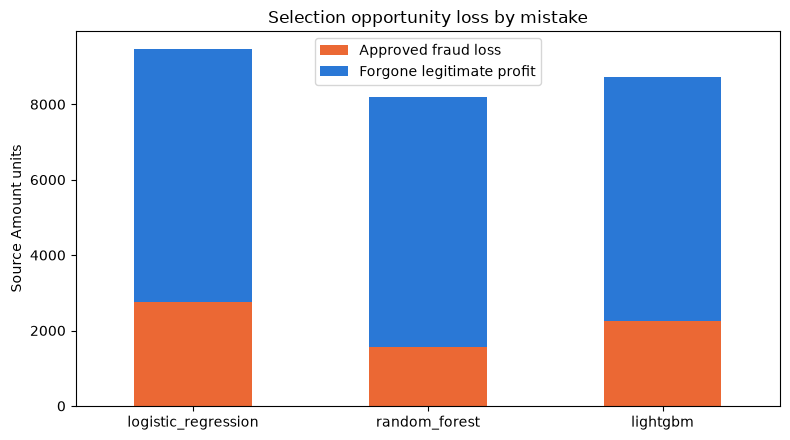

In [3]:
learned = summary.loc[summary.model.isin(["logistic_regression", "random_forest", "lightgbm"])].set_index("model")
fig, ax = plt.subplots(figsize=(8, 4.5))
learned[["approved_fraud_amount", "forgone_legitimate_margin"]].rename(columns={"approved_fraud_amount": "Approved fraud loss", "forgone_legitimate_margin": "Forgone legitimate profit"}).plot.bar(stacked=True, ax=ax, color=["#eb6834", "#2a78d6"])
ax.set(title="Selection opportunity loss by mistake", ylabel="Source Amount units", xlabel="")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(root / "reports/figures/selection-error-costs.png", dpi=160, bbox_inches="tight")
plt.show()

## Representative payments

The categories count **payments**. For the displayed examples, repeated V1–V28/Amount patterns appear once. A caught fraud has zero modeled loss; it is shown to contrast with missed frauds. Scores across models show decisions, not the reason for an individual score.

In [4]:
cases = pd.read_csv(root / report["case_studies"]["path"])
print(report["case_category_counts"])
display(cases.drop(columns="pattern_group_id").round(3))
errors = pd.read_csv(root / report["expensive_errors"]["path"])
display(errors.loc[errors.model.isin(["random_forest", "lightgbm"]), ["source_row_id", "model", "Class", "Amount", "score", "simulated_cost", "error_type"]].head(12).round(3))

{'fraud_missed_by_both_trees': 15, 'fraud_caught_by_both_trees': 59, 'fraud_tree_decisions_disagree': 2, 'legitimate_canceled_by_either_tree': 9}


,source_row_id,category,Class,Amount,Time,logistic_regression_score,logistic_regression_canceled,random_forest_score,random_forest_canceled,lightgbm_score,lightgbm_canceled
0,151196,fraud_missed_by_both_trees,1,571.48,94952.0,0.002,False,0.049,False,0.019,False
1,145800,fraud_missed_by_both_trees,1,451.27,87202.0,0.004,False,0.000,False,0.003,False
2,192687,fraud_missed_by_both_trees,1,276.17,129808.0,0.002,False,0.000,False,0.000,False
3,124036,fraud_missed_by_both_trees,1,129.00,77154.0,0.001,False,0.000,False,0.000,False
4,112840,fraud_missed_by_both_trees,1,45.03,72824.0,0.002,False,0.000,False,0.000,False
5,81609,fraud_caught_by_both_trees,1,1389.56,59011.0,0.492,True,0.852,True,0.995,True
6,95597,fraud_caught_by_both_trees,1,1354.25,65385.0,0.554,True,0.732,True,1.000,True
7,233258,fraud_caught_by_both_trees,1,996.27,147501.0,0.474,True,0.405,True,0.612,True
8,141260,fraud_caught_by_both_trees,1,512.25,84204.0,1.000,True,0.900,True,1.000,True
9,99506,fraud_caught_by_both_trees,1,489.71,67150.0,0.396,True,0.935,True,1.000,True


,source_row_id,model,Class,Amount,score,simulated_cost,error_type
2,274771,random_forest,0,25691.16,0.574,6422.79,canceled_legitimate
3,274771,lightgbm,0,25691.16,0.997,6422.79,canceled_legitimate
50,94218,lightgbm,1,720.38,0.018,720.38,approved_fraud
88,151196,random_forest,1,571.48,0.049,571.48,approved_fraud
89,151196,lightgbm,1,571.48,0.019,571.48,approved_fraud
146,145800,random_forest,1,451.27,0.000,451.27,approved_fraud
147,145800,lightgbm,1,451.27,0.003,451.27,approved_fraud
396,192687,random_forest,1,276.17,0.000,276.17,approved_fraud
397,192687,lightgbm,1,276.17,0.000,276.17,approved_fraud
470,70036,random_forest,0,662.00,0.272,165.50,canceled_legitimate


## Which inputs the trees use

Random Forest impurity reduction and LightGBM split gain are different importance measures, each normalized within its model. They describe how the fitted tree used an input. They do **not** establish a causal effect or explain a specific payment. PCA component names have no published business meaning.

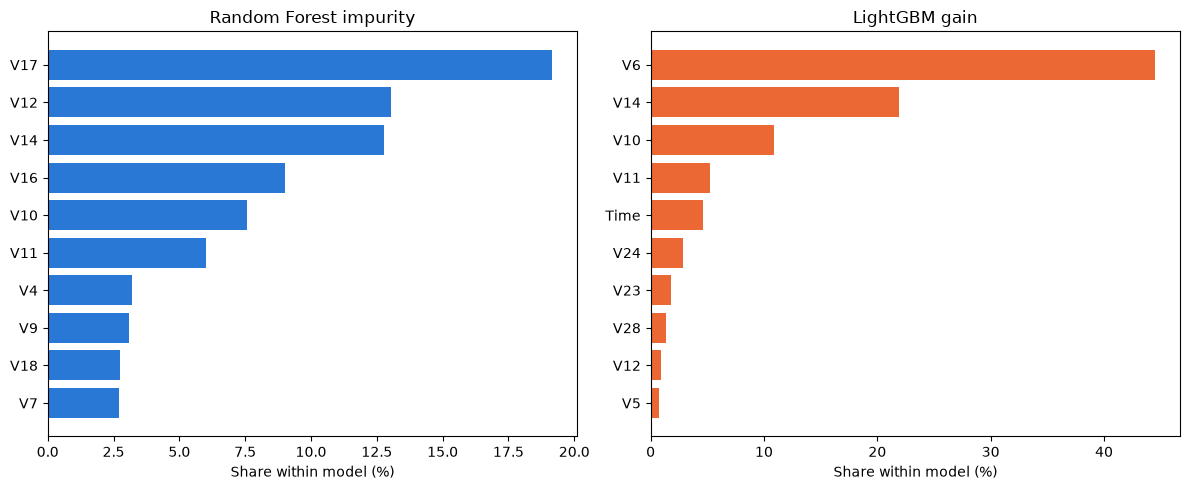

,model,feature,importance_type,relative_importance_pct
0,lightgbm,V6,gain,44.48
1,lightgbm,V14,gain,21.92
2,lightgbm,V10,gain,10.84
3,lightgbm,V11,gain,5.24
4,lightgbm,Time,gain,4.61
30,random_forest,V17,impurity,19.15
31,random_forest,V12,impurity,13.06
32,random_forest,V14,impurity,12.77
33,random_forest,V16,impurity,9.00
34,random_forest,V10,impurity,7.56


In [5]:
importance = pd.read_csv(root / report["feature_importance"]["path"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, title in zip(axes, ["random_forest", "lightgbm"], ["Random Forest impurity", "LightGBM gain"]):
    top = importance.loc[importance.model.eq(name)].head(10).iloc[::-1]
    ax.barh(top.feature, top.relative_importance_pct, color="#2a78d6" if name == "random_forest" else "#eb6834")
    ax.set(title=title, xlabel="Share within model (%)")
fig.tight_layout()
fig.savefig(root / "reports/figures/selection-tree-feature-importance.png", dpi=160, bbox_inches="tight")
plt.show()
display(importance.groupby("model").head(5).round(2))

## LightGBM contributions for individual payments

LightGBM's native feature contributions split a prediction's **raw log-odds** into a base value and one contribution per input. The analysis script checks that all 30 contributions plus the base reproduce each raw score and saved probability. The table and chart show only the five largest absolute contributions per case; omitted inputs can offset them. Positive values raise the model score, negative values lower it. This is a description of this fitted model's calculation, not a causal or business explanation of fraud.

,source_row_id,category,feature,feature_value,log_odds_contribution,base_log_odds,full_raw_log_odds,predicted_probability
0,151196,fraud_missed_by_both_trees,V4,4.821,3.061,-12.336,-3.940,0.019
1,151196,fraud_missed_by_both_trees,V17,2.203,1.517,-12.336,-3.940,0.019
2,151196,fraud_missed_by_both_trees,Amount,571.480,0.926,-12.336,-3.940,0.019
3,151196,fraud_missed_by_both_trees,V8,-0.526,0.669,-12.336,-3.940,0.019
4,151196,fraud_missed_by_both_trees,V10,-0.358,0.491,-12.336,-3.940,0.019
50,94218,fraud_tree_decisions_disagree,V6,0.106,-39.924,-12.336,-4.016,0.018
51,94218,fraud_tree_decisions_disagree,V10,-3.625,19.551,-12.336,-4.016,0.018
52,94218,fraud_tree_decisions_disagree,V11,5.268,18.610,-12.336,-4.016,0.018
53,94218,fraud_tree_decisions_disagree,V24,0.035,-9.658,-12.336,-4.016,0.018
54,94218,fraud_tree_decisions_disagree,Time,64785.000,7.449,-12.336,-4.016,0.018


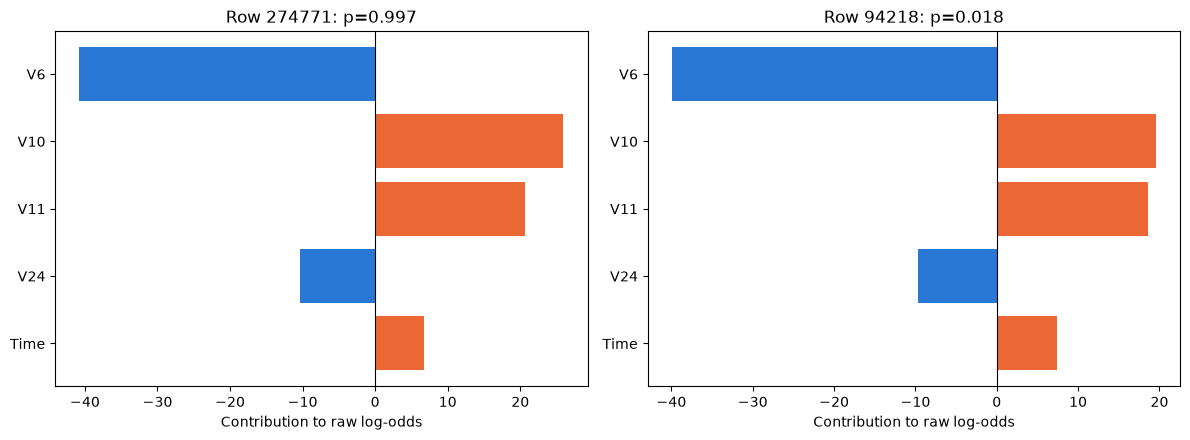

In [6]:
local = pd.read_csv(root / report["lightgbm_local_contributions"]["path"])
selected_ids = [274771, 94218, 151196]
display(local.loc[local.source_row_id.isin(selected_ids), ["source_row_id", "category", "feature", "feature_value", "log_odds_contribution", "base_log_odds", "full_raw_log_odds", "predicted_probability"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, source_id in zip(axes, selected_ids[:2]):
    item = local.loc[local.source_row_id.eq(source_id)].iloc[::-1]
    ax.barh(item.feature, item.log_odds_contribution, color=["#eb6834" if x > 0 else "#2a78d6" for x in item.log_odds_contribution])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=f"Row {source_id}: p={item.predicted_probability.iloc[0]:.3f}", xlabel="Contribution to raw log-odds")
fig.tight_layout()
fig.savefig(root / "reports/figures/selection-local-contributions.png", dpi=160, bbox_inches="tight")
plt.show()

**Decision:** Carry both trees into calibration. The cost ranking is sensitive to a handful of expensive payments, and the current probabilities are uncalibrated. Keep the all-payment comparison primary; inspect outliers as sensitivity checks without dropping them from the main result. Do not invent a customer, merchant, or clock-hour explanation for anonymized components and elapsed Time.